# 07 · Deep vs linear, and strategy & execution (Day 5: Stages 10 and 8)
**Microstructure Alpha · development days D1–D5 for fitting, selection day D6 for every choice · test days D7–D8 are NOT opened here**

| Part | Content |
|---|---|
| A | **Deep vs linear** (research clock, 1 s buckets, last 32 s of history): linear OFI1 · ridge on the full 32×6 window (the control that isolates nonlinearity) · LightGBM on multi-scale window sums · small causal temporal CNN. Joint targets: next 1 s, 5 s, 30 s. Dev walk-forward plus the D6 check. **Complexity is accepted only if it pays.** |
| B0 | **Trading signal on the received clock**: next-1 s mid-change forecast from OFI, the empirical microprice and Hawkes excitation, fit on D1–D5 and frozen |
| B1 | **Latency decay**: information coefficient of the signal against the realized exchange-time move after a send latency L = 0…1000 ms; alpha half-life |
| A* | **Track A — execution alpha (headline)**: 50 ETH parents over 10 min at random times and sides; TWAP vs OFI-timed marketable children; implementation shortfall vs arrival mid with bootstrap CIs, by latency and size |
| B* | **Track B — skewed touch market making**: queue position from the real book, pessimistic and optimistic queue models, latency, inventory limits, markouts, PnL attribution, break-even maker fee across the pre-registered fee grid, capacity, kill criteria |
| C* | **Track C — directional taker**: trades only where the forecast exceeds the round-trip cost |

**Frozen rules applied here (from the protocol and earlier notebooks).** Fees are reported across the full pre-registered grid; the headline row uses `FEE_MAKER_BP` / `FEE_TAKER_BP` below, which must be grid points. Decisions use only information received by the decision time (received clock). Orders reach the exchange after the send latency, and fills walk the exchange-time book. Parameters (θ thresholds, model choice) are tuned on development days and frozen before D6. Funding payments are **not modelled**: the dataset has no funding-rate series. All holding periods are sub-hour.

**Requirements:** `pip install lightgbm torch` (CPU torch is enough). Close other notebook kernels first. **Runtime:** about 1–2 hours.

In [1]:
# ===================== CONFIG =====================
from pathlib import Path
OUT_DIR        = Path(r"C:\microalpha_proj\microoutput")
FEE_MAKER_BP   = 2.0       # your account tier; must be in the protocol fee grid (maker: -0.5, 0, 1, 2)
FEE_TAKER_BP   = 5.0       # (taker: 2.5, 4, 5)
W              = 32        # Part A history window (1 s buckets)
RUN_CNN        = True
CNN_EPOCHS     = 3
N_PARENTS_SEL  = 300       # Track A parents on the selection day
N_PARENTS_DEV  = 60        # per development day, for calibrating θ_A
PARENT_ETH, PARENT_MIN, SLOT_S = 50, 10, 30
THETA_A_GRID   = [0.1, 0.25, 0.5, 1.0, 2.0, 1e9]     # ticks; 1e9 = never early (pure TWAP timing)
THETA_B_GRID   = [0.25, 0.5, 1.0, 2.0, 1e9]          # ticks; 1e9 = no skew
MM_Q_ETH, MM_INV_MAX_ETH = 1.0, 10.0
STRICT         = True
# ==================================================

In [2]:
import sys, os, time, math, gc, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd()))
import ma_lib
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60)
P = ma_lib.load_protocol(OUT_DIR)
REP, EVT, FEA, BOOK = OUT_DIR / 'reports', OUT_DIR / 'events', OUT_DIR / 'features', OUT_DIR / 'book'
DEV = P['data_split']['development']; SEL = P['data_split']['selection'][0]; TEST = P['data_split']['test']
LAT_GRID = P['grid']['latency_grid_ms']; FEE_GRID = P['costs']['fee_grid_bp']; SEED = P['inference']['seed']; EMB_MIN = P['purge_embargo']['embargo_minutes']
assert FEE_MAKER_BP in FEE_GRID['maker'] and FEE_TAKER_BP in FEE_GRID['taker'], 'headline fees must be pre-registered grid points'
have = [d for d in DEV + [SEL] if (FEA / 'ex' / f'feat_ex_{d}.parquet').exists() and (FEA / 'rx' / f'feat_rx_{d}.parquet').exists()]
DEV = [d for d in DEV if d in have]
print('protocol OK | dev:', DEV, '| selection:', SEL, '| test days (not opened):', TEST, '| latency grid:', LAT_GRID)
if STRICT and (len(DEV) != 5 or SEL not in have): raise RuntimeError('development and selection days are required')
def emb_mask(t_end, day):
    t0 = pd.Timestamp(day).value // 10**6; return (t_end >= t0 + EMB_MIN * 60_000) & (t_end <= t0 + 86_400_000 - EMB_MIN * 60_000)
def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); adj = np.empty_like(p); run = 0.0
    for r, i in enumerate(o): run = max(run, min(1.0, (len(p) - r) * p[i])); adj[i] = run
    return adj

protocol OK | dev: ['2026-09-07', '2026-09-08', '2026-09-09', '2026-09-10', '2026-09-11'] | selection: 2026-09-12 | test days (not opened): ['2026-09-13', '2026-09-14'] | latency grid: [0, 50, 130, 250]


## A · Deep vs linear (research clock)
Six channels per 1 s bucket: level-1 OFI, OFI at levels 2–5, trade imbalance, queue imbalance (end of bucket), signed taker-order count, net sweeps. Each sample uses the last 32 buckets. Targets: mid change over the next 1, 5 and 30 s (ticks). Channels are standardized with training statistics. Ridge and LightGBM tune on the last training day; the CNN picks its best epoch there.

**Acceptance rule (written before running):** a complex model is accepted for trading only if, at the **1 s** target, it beats ridge in a Diebold–Mariano test (Holm-adjusted across complex models × targets, 5%) on the dev walk-forward **and** has higher OOS R² than ridge on D6.

In [3]:
ACOLS = ['t_end', 'valid', 'bp1', 'ap1', 'bq1', 'aq1', 'ofi1', 'ofi2', 'ofi3', 'ofi4', 'ofi5', 'v_buy', 'v_sell', 'n_buy_orders', 'n_sell_orders', 'n_sweep_buy', 'n_sweep_sell']
HZ = [1, 5, 30]
def day_buckets(d):
    g = pd.read_parquet(FEA / 'ex' / f'feat_ex_{d}.parquet', columns=ACOLS); k = 10; n = len(g) // k * k; g = g.iloc[:n]; idx = np.arange(n) // k
    S = lambda c: np.bincount(idx, weights=g[c].to_numpy(float))
    bq, aq = g.bq1.to_numpy(float)[k - 1::k], g.aq1.to_numpy(float)[k - 1::k]
    F = np.c_[S('ofi1') / 1000, (S('ofi2') + S('ofi3') + S('ofi4') + S('ofi5')) / 1000, (S('v_buy') - S('v_sell')) / 1000,
              (bq - aq) / np.where(bq + aq > 0, bq + aq, np.nan), S('n_buy_orders') - S('n_sell_orders'), S('n_sweep_buy') - S('n_sweep_sell')].astype(np.float32)
    m2 = (g.bp1 + g.ap1).to_numpy(float)[k - 1::k]; v = np.bincount(idx, weights=(~g.valid.to_numpy()).astype(float)) == 0
    t = g.t_end.to_numpy()[k - 1::k]; nb = len(t)
    Y = np.full((nb, 3), np.nan)
    for j, h in enumerate(HZ): Y[:-h, j] = (m2[h:] - m2[:-h]) / 2.0
    win_ok = pd.Series(v.astype(float)).rolling(W, min_periods=W).min().to_numpy() == 1
    fut_ok = pd.Series(v[::-1].astype(float)).rolling(max(HZ) + 1, min_periods=1).min().to_numpy()[::-1] == 1
    mask = win_ok & fut_ok & np.isfinite(Y).all(1) & np.isfinite(F).all(1) & emb_mask(t, d)
    return dict(F=np.nan_to_num(F), Y=Y, mask=mask, t=t)
AD = {d: day_buckets(d) for d in DEV + [SEL]}
print({d: int(a['mask'].sum()) for d, a in AD.items()}, 'samples per day')

{'2026-09-07': 84984, '2026-09-08': 84296, '2026-09-09': 84892, '2026-09-10': 83290, '2026-09-11': 84582, '2026-09-12': 81580} samples per day


In [4]:
import importlib.util
HAVE_LGB = importlib.util.find_spec('lightgbm') is not None; HAVE_TORCH = importlib.util.find_spec('torch') is not None
if HAVE_LGB: import lightgbm as lgb
if HAVE_TORCH and RUN_CNN:
    import torch, torch.nn as nn
    torch.set_num_threads(max(1, os.cpu_count() or 1)); torch.manual_seed(SEED)
    class TCN(nn.Module):                                 # causal dilated conv stack, receptive field 31 buckets
        def __init__(self, c=6, h=16, out=3):
            super().__init__(); self.convs = nn.ModuleList(); self.dil = [1, 2, 4, 8]
            for i, dl in enumerate(self.dil): self.convs.append(nn.Conv1d(c if i == 0 else h, h, 3, dilation=dl))
            self.head = nn.Linear(h, out)
        def forward(self, x):                             # x: (B, C, W)
            for conv, dl in zip(self.convs, self.dil): x = torch.relu(conv(nn.functional.pad(x, (2 * dl, 0))))
            return self.head(x[:, :, -1])
print('lightgbm available:', HAVE_LGB, '| torch available:', HAVE_TORCH and RUN_CNN)

def stack(days, std=None):
    F = [AD[d]['F'] for d in days]
    if std is None:
        allF = np.vstack([f[AD[d]['mask']] for f, d in zip(F, days)]); std = (allF.mean(0), allF.std(0) + 1e-9)
    out = []
    for f, d in zip(F, days):
        Fs = (f - std[0]) / std[1]; idx = np.nonzero(AD[d]['mask'])[0]
        out.append((Fs.astype(np.float32), idx, AD[d]['Y'][idx], AD[d]['t'][idx], f))
    return out, std
def flat_windows(Fs, idx):                                # (m, W*C) without materializing all windows at once
    V = np.lib.stride_tricks.sliding_window_view(Fs, W, axis=0)           # (n-W+1, C, W)
    return V[idx - W + 1].reshape(len(idx), -1)
def fit_predict(train_days, test_day):
    tr, std = stack(train_days); te, _ = stack([test_day], std)
    inner_tr, inner_va = (tr[:-1], tr[-1:]) if len(tr) >= 2 else (tr, tr)
    Fte, ite, Yte, tte, rawte = te[0]
    preds = {}
    # linear OFI1 (current bucket)
    x = np.concatenate([r[4][r[1], 0] for r in tr]); Y = np.vstack([r[2] for r in tr])
    Z = np.c_[np.ones(len(x)), x]; c = np.linalg.lstsq(Z, Y, rcond=None)[0]; preds['linear_ofi1'] = np.c_[np.ones(len(ite)), rawte[ite, 0]] @ c
    # ridge on the full window (Gram accumulated per day; alpha chosen on the inner validation day)
    def gram(parts):
        p = W * 6; G = np.zeros((p, p)); g = np.zeros((p, 3)); sx = np.zeros(p); sy = np.zeros(3); n = 0
        for Fs, idx, Yd, _, _ in parts:
            for i in range(0, len(idx), 50_000):
                X = flat_windows(Fs, idx[i:i + 50_000]).astype(np.float64); y = Yd[i:i + 50_000]
                G += X.T @ X; g += X.T @ y; sx += X.sum(0); sy += y.sum(0); n += len(y)
        mx, my = sx / n, sy / n; return G - n * np.outer(mx, mx), g - n * np.outer(mx, my), mx, my
    Gi, gi, mxi, myi = gram(inner_tr); Fv, iv, Yv, _, _ = inner_va[0]; Xv = flat_windows(Fv, iv).astype(np.float64)
    alphas = np.logspace(0, 6, 13)
    a_best = min(alphas, key=lambda a: np.mean((Yv[:, 0] - myi[0] - (Xv - mxi) @ np.linalg.solve(Gi + a * np.eye(len(gi)), gi[:, 0])) ** 2))
    G, g, mx, my = gram(tr); B = np.linalg.solve(G + a_best * np.eye(len(g)), g)
    Xte = flat_windows(Fte, ite).astype(np.float64); preds['ridge_window'] = my + (Xte - mx) @ B
    # LightGBM on multi-scale window sums
    if HAVE_LGB:
        S = lambda parts: np.vstack([ma_lib.summary_windows(r[0])[r[1]] for r in parts])
        Str_, Sva, Ste = S(inner_tr), S(inner_va), ma_lib.summary_windows(Fte)[ite]
        Ytr_i, Yva = np.vstack([r[2] for r in inner_tr]), inner_va[0][2]
        Sall, Yall = S(tr), np.vstack([r[2] for r in tr]); out = []
        for j in range(3):
            prm = dict(objective='l2', learning_rate=0.05, num_leaves=31, min_data_in_leaf=500, feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, seed=SEED, verbose=-1)
            m = lgb.train(prm, lgb.Dataset(Str_, Ytr_i[:, j]), 400, valid_sets=[lgb.Dataset(Sva, Yva[:, j])], callbacks=[lgb.early_stopping(30, verbose=False)])
            m2 = lgb.train(prm, lgb.Dataset(Sall, Yall[:, j]), max(m.best_iteration, 20)); out.append(m2.predict(Ste))
        preds['lightgbm'] = np.c_[out[0], out[1], out[2]]
    # causal temporal CNN
    if HAVE_TORCH and RUN_CNN:
        ysd = np.vstack([r[2] for r in tr]).std(0) + 1e-9
        def batches(parts, bs, shuffle):
            items = [(pi, i) for pi, r in enumerate(parts) for i in range(0, len(r[1]), bs)]
            if shuffle: np.random.default_rng(SEED).shuffle(items)
            for pi, i in items:
                Fs, idx, Yd, _, _ = parts[pi]; ii = idx[i:i + bs]
                x = np.lib.stride_tricks.sliding_window_view(Fs, W, axis=0)[ii - W + 1]
                yield torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy((Yd[i:i + bs] / ysd).astype(np.float32))
        def predict(model, parts):
            model.eval(); out = []
            with torch.no_grad():
                for xb, _ in batches(parts, 8192, False): out.append(model(xb).numpy())
            return np.vstack(out) * ysd
        model = TCN(); opt = torch.optim.Adam(model.parameters(), lr=1e-3); best = (np.inf, None)
        for ep in range(CNN_EPOCHS):
            model.train()
            for xb, yb in batches(inner_tr, 4096, True):
                opt.zero_grad(); loss = ((model(xb) - yb) ** 2).mean(); loss.backward(); opt.step()
            vl = np.mean((predict(model, inner_va) - inner_va[0][2]) ** 2)
            if vl < best[0]: best = (vl, {k: v.clone() for k, v in model.state_dict().items()}, ep + 1)
        model = TCN(); opt = torch.optim.Adam(model.parameters(), lr=1e-3)
        for ep in range(best[2]):                         # refit on all training days for the chosen number of epochs
            model.train()
            for xb, yb in batches(tr, 4096, True):
                opt.zero_grad(); loss = ((model(xb) - yb) ** 2).mean(); loss.backward(); opt.step()
        preds['cnn'] = predict(model, te)
    return preds, Yte, tte
t0 = time.time(); WF = []
for i in range(1, len(DEV)):
    pr, Yte, tte = fit_predict(DEV[:i], DEV[i]); WF.append((pr, Yte)); print(f'walk-forward fold → {DEV[i]} ({time.time()-t0:.0f}s)')
prS, YS, tS = fit_predict(DEV, SEL); print(f'final fit D1–D5 → {SEL} ({time.time()-t0:.0f}s)')
models = list(WF[0][0].keys()); Ywf = np.vstack([y for _, y in WF])
r2 = []
for mname in models:
    Pw = np.vstack([p[mname] for p, _ in WF])
    for j, h in enumerate(HZ):
        r2.append(dict(model=mname, target_s=h, oos_r2_dev_wf=ma_lib.oos_r2(Ywf[:, j], Pw[:, j]), oos_r2_selection_day=ma_lib.oos_r2(YS[:, j], prS[mname][:, j])))
r2 = pd.DataFrame(r2); display(r2.pivot(index='model', columns='target_s', values=['oos_r2_dev_wf', 'oos_r2_selection_day']).round(5))
dm = []
for mname in [m for m in models if m in ('lightgbm', 'cnn')]:
    Pw = np.vstack([p[mname] for p, _ in WF]); Pr = np.vstack([p['ridge_window'] for p, _ in WF])
    for j, h in enumerate(HZ):
        st, p, _ = ma_lib.dm_test((Ywf[:, j] - Pr[:, j]) ** 2, (Ywf[:, j] - Pw[:, j]) ** 2, h + 5); dm.append(dict(model=mname, target_s=h, dm_stat=st, p=p))
dm = pd.DataFrame(dm)
if len(dm):
    dm['p_holm'] = holm(dm.p); display(dm.round(5))
accepted = None
for mname in ('lightgbm', 'cnn'):
    row = dm[(dm.model == mname) & (dm.target_s == 1)] if len(dm) else pd.DataFrame()
    if len(row) and row.p_holm.iloc[0] < 0.05:
        s_m = r2[(r2.model == mname) & (r2.target_s == 1)].oos_r2_selection_day.iloc[0]; s_r = r2[(r2.model == 'ridge_window') & (r2.target_s == 1)].oos_r2_selection_day.iloc[0]
        if s_m > s_r and (accepted is None or s_m > r2[(r2.model == accepted) & (r2.target_s == 1)].oos_r2_selection_day.iloc[0]): accepted = mname
SIGNAL_MODEL = 'lightgbm' if accepted == 'lightgbm' else 'linear'
print('complex model accepted:', accepted or 'none', '→ trading signal model:', SIGNAL_MODEL, '(the CNN, if accepted, is reported but not deployed in the received-clock pipeline)' if accepted == 'cnn' else '')
r2.to_csv(REP / '07_deep_vs_linear.csv', index=False); dm.to_csv(REP / '07_deep_vs_linear_dm.csv', index=False)
del AD; _ = gc.collect()

lightgbm available: False | torch available: True
walk-forward fold → 2026-09-08 (27s)
walk-forward fold → 2026-09-09 (72s)
walk-forward fold → 2026-09-10 (128s)
walk-forward fold → 2026-09-11 (203s)
final fit D1–D5 → 2026-09-12 (297s)


oos_r2_dev_wf                   oos_r2_selection_day                  
target_s                1        5        30                   1        5        30
model                                                                              
cnn                0.01971  0.01333  0.00266             -0.01796  0.01225  0.00399
linear_ofi1        0.00920  0.00493  0.00125              0.00808  0.00572  0.00099
ridge_window       0.03609  0.02083  0.00357             -0.00077  0.01797  0.00650

,model,target_s,dm_stat,p,p_holm
0,cnn,1,-16.64896,1.00000,1.0
1,cnn,5,-4.03484,0.99997,1.0
2,cnn,30,-0.20439,0.58098,1.0


complex model accepted: none → trading signal model: linear 


## B0 · Trading signal on the received clock (frozen on D1–D5)
At each 100 ms decision time *t* on the **received** clock, the signal uses only what had arrived by *t*:
- level-1 OFI in the current bin and over the last 1 s
- trade imbalance over 1 s
- queue imbalance
- the empirical microprice (queue-imbalance decile → mean next move, fitted on D1–D5)
- net and total Hawkes excitation, with taker orders timed at their batch's **received** time and parameters taken from notebook 06's development-day fits

The target is the next-1 s mid change on the received clock. The model is `SIGNAL_MODEL` from Part A, fit once on D1–D5 and then frozen.

In [5]:
hh = pd.read_csv(REP / '06_hawkes_hourly.csv'); hh = hh[hh.date.isin(DEV)]
HK_BETA = float(hh.beta.mode().iloc[0]); HK_A = np.array([[hh.A_bb.median(), hh.A_bs.median()], [hh.A_sb.median(), hh.A_ss.median()]])
RCOLS = ['t_end', 'valid', 'bp1', 'ap1', 'bq1', 'aq1', 'ofi1', 'v_buy', 'v_sell']
def order_times_R(d):
    u_, R_ = [], []
    for hr in range(24):
        f = EVT / d / f'events_{d}_{hr:02d}.parquet'
        if f.exists(): e = pd.read_parquet(f, columns=['u', 'R']); u_.append(e.u.to_numpy()); R_.append(e.R.to_numpy() // 1_000_000)
    u_, R_ = np.concatenate(u_), np.concatenate(R_)
    o = pd.read_parquet(EVT / f'taker_orders_{d}.parquet', columns=['u_post', 'sign', 'usable']); o = o[o.usable]
    j = np.clip(np.searchsorted(u_, o.u_post.to_numpy()), 0, len(u_) - 1); ok = u_[j] == o.u_post.to_numpy()
    t = R_[j][ok]; ty = (o.sign.to_numpy()[ok] < 0).astype(np.int64); oo = np.argsort(t, kind='stable'); return t[oo], ty[oo]
def rx_features(d):
    g = pd.read_parquet(FEA / 'rx' / f'feat_rx_{d}.parquet', columns=RCOLS); d0 = pd.Timestamp(d).value // 10**6
    o1 = g.ofi1.to_numpy(float) / 1000; ti = (g.v_buy - g.v_sell).to_numpy(float) / 1000
    roll = lambda x: pd.Series(x).rolling(10, min_periods=1).sum().to_numpy()
    bq, aq = g.bq1.to_numpy(float), g.aq1.to_numpy(float); qi = (bq - aq) / np.where(bq + aq > 0, bq + aq, np.nan)
    tm, ty = order_times_R(d)
    E = ma_lib._hawkes_excitation_grid((tm - d0) / 1000.0, ty, (g.t_end.to_numpy() - d0) / 1000.0 + 1e-9, HK_A, HK_BETA, 2)
    X = np.c_[o1, roll(o1), roll(ti), np.nan_to_num(qi), E[:, 0] - E[:, 1], E[:, 0] + E[:, 1]]
    m2 = (g.bp1 + g.ap1).to_numpy(float); y = np.full(len(m2), np.nan); y[:-10] = (m2[10:] - m2[:-10]) / 2.0
    v = g.valid.to_numpy(); fut = np.r_[v[10:], np.zeros(10, bool)]
    mask = v & fut & np.isfinite(qi) & emb_mask(g.t_end.to_numpy(), d)
    return dict(t=g.t_end.to_numpy(), X=X, qi=np.nan_to_num(qi), y=y, mask=mask, valid=v)
RX = {}
for d in DEV + [SEL]:
    RX[d] = rx_features(d); print(f'{d}: received-clock features ({RX[d]["mask"].sum():,} usable bins)')
qtr = np.concatenate([RX[d]['qi'][RX[d]['mask']] for d in DEV]); ytr = np.concatenate([RX[d]['y'][RX[d]['mask']] for d in DEV])
edges = np.unique(np.quantile(qtr, np.linspace(0, 1, 11))); edges[0], edges[-1] = -np.inf, np.inf
bt = np.digitize(qtr, edges[1:-1]); micro_map = np.bincount(bt, weights=ytr, minlength=len(edges) - 1) / np.maximum(np.bincount(bt, minlength=len(edges) - 1), 1)
FEATS = ['ofi1_bin', 'ofi1_1s', 'ti_1s', 'qi', 'hawkes_net', 'hawkes_tot', 'micro']
def design(d): return np.c_[RX[d]['X'], micro_map[np.digitize(RX[d]['qi'], edges[1:-1])]]
Xtr = np.vstack([design(d)[RX[d]['mask']] for d in DEV])
if SIGNAL_MODEL == 'lightgbm':
    sig_model = lgb.train(dict(objective='l2', learning_rate=0.05, num_leaves=31, min_data_in_leaf=2000, seed=SEED, verbose=-1), lgb.Dataset(Xtr, ytr), 300)
    predict_sig = lambda X: sig_model.predict(X)
else:
    coef = np.linalg.lstsq(np.c_[np.ones(len(ytr)), Xtr], ytr, rcond=None)[0]; predict_sig = lambda X: coef[0] + X @ coef[1:]
    print('signal coefficients:', dict(zip(['const'] + FEATS, np.round(coef, 5))))
for d in DEV + [SEL]:
    RX[d]['f'] = np.where(RX[d]['valid'], predict_sig(design(d)), np.nan)
r2_sel = ma_lib.oos_r2(RX[SEL]['y'][RX[SEL]['mask']], RX[SEL]['f'][RX[SEL]['mask']])
print(f'signal OOS R² on the selection day (received clock, next 1 s): {r2_sel:.5f}; in-sample dev R² {ma_lib.oos_r2(ytr, predict_sig(Xtr)):.5f}')
def f_at(d, t_local):                                     # forecast known at local time t (last received-clock bin ending at or before t)
    i = np.searchsorted(RX[d]['t'], np.asarray(t_local), side='right') - 1
    return np.where(i >= 0, RX[d]['f'][np.maximum(i, 0)], np.nan)

2026-09-07: received-clock features (850,385 usable bins)
2026-09-08: received-clock features (843,484 usable bins)
2026-09-09: received-clock features (848,643 usable bins)
2026-09-10: received-clock features (833,148 usable bins)
2026-09-11: received-clock features (845,836 usable bins)
2026-09-12: received-clock features (816,311 usable bins)
signal coefficients: {'const': -0.0328, 'ofi1_bin': 0.00726, 'ofi1_1s': 0.00071, 'ti_1s': 0.0004, 'qi': 0.91165, 'hawkes_net': 0.04743, 'hawkes_tot': 0.00417, 'micro': 0.77799}
signal OOS R² on the selection day (received clock, next 1 s): -0.00691; in-sample dev R² 0.04125


## B1 · Latency decay of the signal (selection day)
IC(L) is the correlation between the forecast known at local time *t* and the realized **exchange-time** mid change over (t + L, t + L + 1 s]: what a trader acting after send latency L could capture. The alpha half-life is the latency at which IC falls to half its L = 0 value.

,latency_ms,ic,n
0,0,0.1306,816310
1,50,0.1214,816309
2,100,0.1214,816309
3,130,0.1140,816308
5,200,0.1140,816308
6,250,0.1081,816307
11,500,0.0979,816305
21,1000,0.0817,816300


alpha half-life ≈ inf ms (IC at 0 ms = 0.1306)


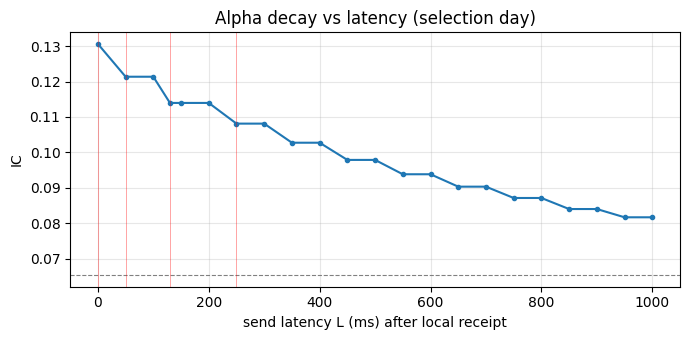

In [6]:
ge = pd.read_parquet(FEA / 'ex' / f'feat_ex_{SEL}.parquet', columns=['t_end', 'valid', 'bp1', 'ap1']); te_ = ge.t_end.to_numpy(); me_ = (ge.bp1 + ge.ap1).to_numpy(float) / 2; ve_ = ge.valid.to_numpy()
def mid_ex(t):
    i = np.clip(np.searchsorted(te_, t, side='left'), 0, len(te_) - 1); return me_[i], ve_[i]
tt = RX[SEL]['t'][RX[SEL]['mask']]; ff = RX[SEL]['f'][RX[SEL]['mask']]
lat = []
for L in sorted(set(list(range(0, 1001, 50)) + LAT_GRID)):
    a, va = mid_ex(tt + L); b, vb = mid_ex(tt + L + 1000); ok = va & vb & np.isfinite(ff)
    lat.append(dict(latency_ms=L, ic=np.corrcoef(ff[ok], (b - a)[ok])[0, 1], n=int(ok.sum())))
lat = pd.DataFrame(lat); ic0 = lat.ic.iloc[0]
below = lat[lat.ic <= ic0 / 2]; HALF_LIFE_MS = float(below.latency_ms.iloc[0]) if len(below) else float('inf')
display(lat[lat.latency_ms.isin([0, 50, 100, 130, 200, 250, 500, 1000])].round(4)); print(f'alpha half-life ≈ {HALF_LIFE_MS} ms (IC at 0 ms = {ic0:.4f})')
fig, ax = plt.subplots(figsize=(7, 3.5)); ax.plot(lat.latency_ms, lat.ic, 'o-', ms=3); ax.axhline(ic0 / 2, color='grey', ls='--', lw=.8)
for L in LAT_GRID: ax.axvline(L, color='r', lw=.5, alpha=.5)
ax.set_xlabel('send latency L (ms) after local receipt'); ax.set_ylabel('IC'); ax.set_title('Alpha decay vs latency (selection day)'); ax.grid(alpha=.3)
plt.tight_layout(); fig.savefig(REP / '07_latency_decay.png', dpi=110); plt.show(); lat.to_csv(REP / '07_latency_decay.csv', index=False)

## Track A — execution alpha (headline)
A **parent** order (default 50 ETH, random side) is executed over 10 minutes in 20 slots of 30 s with equal child orders. Children are **marketable** and walk the exchange-time book (top 10, then one tick worse) at arrival time *t + L*.
- **TWAP** sends each child at the start of its slot.
- **OFI-timed** checks the signal every second within the slot and sends early when it predicts the price moving against the parent (side × forecast ≥ θ_A); otherwise it sends at the slot's last second.

**Implementation shortfall** = side × (parent VWAP − arrival mid) / arrival mid, in bp. Both strategies pay the same taker fee, so the paired difference is a real saving. θ_A is chosen on development days at L = 130 ms and frozen. Start times are drawn where the whole window is valid.

In [7]:
def valid_starts(d, n, seed):
    g = pd.read_parquet(FEA / 'ex' / f'feat_ex_{d}.parquet', columns=['t_end', 'valid']); t = g.t_end.to_numpy(); v = g.valid.to_numpy()
    span = PARENT_MIN * 600 + 40                          # bins covering the parent window plus margin
    bad = np.convolve((~v).astype(int), np.ones(span, int), 'full')[span - 1:]
    cand = np.nonzero((bad == 0) & emb_mask(t, d))[0]; cand = cand[cand + span < len(t)]
    rng = np.random.default_rng(seed); pick = np.sort(rng.choice(cand, size=min(n, len(cand)), replace=False))
    return t[pick], np.where(rng.random(len(pick)) < .5, 1, -1)
def child_times(d, starts, sides, theta, L):
    n_sl = PARENT_MIN * 60 // SLOT_S; out = np.zeros((len(starts), n_sl), np.int64)
    for k in range(n_sl):
        ts = starts + k * SLOT_S * 1000
        if theta >= 1e8: out[:, k] = ts
        else:
            grid = ts[:, None] + np.arange(SLOT_S)[None, :] * 1000
            f = f_at(d, grid.ravel()).reshape(grid.shape) * sides[:, None]
            hit = f >= theta; first = np.where(hit.any(1), hit.argmax(1), SLOT_S - 1)
            out[:, k] = ts + first * 1000
    return out + L
def shortfalls(d, starts, sides, child_t, size_eth):
    n_sl = child_t.shape[1]; child = size_eth / n_sl * 1000
    bk = ma_lib.lookup_books(BOOK, d, np.r_[starts, child_t.ravel()])
    mid0 = (bk['bp'][:len(starts), 0] + bk['ap'][:len(starts), 0]) / 2.0
    vw = np.zeros(child_t.shape)
    for i in range(len(starts)):
        for k in range(n_sl):
            j = len(starts) + i * n_sl + k
            vw[i, k] = ma_lib.walk_book(sides[i], bk['ap'][j] if sides[i] > 0 else bk['bp'][j], bk['aq'][j] if sides[i] > 0 else bk['bq'][j], child)
    return sides * (vw.mean(1) - mid0) / mid0 * 1e4
t0 = time.time(); cal = []
for i_d, d in enumerate(DEV):
    st, sd = valid_starts(d, N_PARENTS_DEV, SEED + i_d)
    base = shortfalls(d, st, sd, child_times(d, st, sd, 1e9, 130), PARENT_ETH)
    for th in THETA_A_GRID[:-1]:
        cal.append(dict(date=d, theta=th, saving_bp=np.mean(base - shortfalls(d, st, sd, child_times(d, st, sd, th, 130), PARENT_ETH))))
    print(f'{d}: θ_A calibration ({time.time()-t0:.0f}s)')
cal = pd.DataFrame(cal); cs = cal.groupby('theta').saving_bp.mean(); THETA_A = float(cs.idxmax()) if cs.max() > 0 else 1e9
print('mean saving vs TWAP on development days (bp) by θ_A:', cs.round(4).to_dict(), '→ frozen θ_A =', THETA_A)

2026-09-07: θ_A calibration (17s)
2026-09-08: θ_A calibration (38s)
2026-09-09: θ_A calibration (56s)
2026-09-10: θ_A calibration (74s)
2026-09-11: θ_A calibration (92s)
mean saving vs TWAP on development days (bp) by θ_A: {0.1: 0.2434, 0.25: 0.249, 0.5: 0.2674, 1.0: 0.2865, 2.0: 0.3383} → frozen θ_A = 2.0


In [8]:
rng = np.random.default_rng(SEED + 99)
st, sd = valid_starts(SEL, N_PARENTS_SEL, SEED + 99); rows = []; t0 = time.time()
def boot_ci(x, reps=1000):
    b = np.array([x[rng.integers(0, len(x), len(x))].mean() for _ in range(reps)]); return np.percentile(b, [2.5, 97.5])
for L in LAT_GRID:
    tw = shortfalls(SEL, st, sd, child_times(SEL, st, sd, 1e9, L), PARENT_ETH)
    ot = shortfalls(SEL, st, sd, child_times(SEL, st, sd, THETA_A, L), PARENT_ETH) if THETA_A < 1e8 else tw.copy()
    sv = tw - ot; lo, hi = boot_ci(sv)
    rows.append(dict(latency_ms=L, parents=len(st), twap_shortfall_bp=tw.mean(), ofi_timed_shortfall_bp=ot.mean(), saving_bp=sv.mean(), ci_lo=lo, ci_hi=hi,
                     saving_positive_share=(sv > 0).mean(), all_in_cost_bp_twap=tw.mean() + FEE_TAKER_BP, all_in_cost_bp_timed=ot.mean() + FEE_TAKER_BP))
    print(f'L={L} ms done ({time.time()-t0:.0f}s)')
TA = pd.DataFrame(rows); display(TA.round(4))
cap = []
for size in (10, 50, 200):
    tw = shortfalls(SEL, st, sd, child_times(SEL, st, sd, 1e9, 130), size); ot = shortfalls(SEL, st, sd, child_times(SEL, st, sd, THETA_A, 130), size) if THETA_A < 1e8 else tw
    lo, hi = boot_ci(tw - ot); cap.append(dict(parent_eth=size, twap_shortfall_bp=tw.mean(), ofi_timed_shortfall_bp=ot.mean(), saving_bp=(tw - ot).mean(), ci_lo=lo, ci_hi=hi))
TAcap = pd.DataFrame(cap); print('capacity (L = 130 ms):'); display(TAcap.round(4))
TA.to_csv(REP / '07_trackA.csv', index=False); TAcap.to_csv(REP / '07_trackA_capacity.csv', index=False); cal.to_csv(REP / '07_trackA_calibration.csv', index=False)

L=0 ms done (4s)
L=50 ms done (9s)
L=130 ms done (13s)
L=250 ms done (17s)


,latency_ms,parents,twap_shortfall_bp,ofi_timed_shortfall_bp,saving_bp,ci_lo,ci_hi,saving_positive_share,all_in_cost_bp_twap,all_in_cost_bp_timed
0,0,300,-0.1622,-0.3771,0.2150,0.1812,0.2463,0.7500,4.8378,4.6229
1,50,300,-0.1614,-0.3720,0.2106,0.1785,0.2431,0.7533,4.8386,4.6280
2,130,300,-0.1615,-0.3665,0.2050,0.1725,0.2350,0.7567,4.8385,4.6335
3,250,300,-0.1633,-0.3568,0.1935,0.1614,0.2273,0.7567,4.8367,4.6432


capacity (L = 130 ms):


,parent_eth,twap_shortfall_bp,ofi_timed_shortfall_bp,saving_bp,ci_lo,ci_hi
0,10,-0.1621,-0.3681,0.2061,0.1745,0.2390
1,50,-0.1615,-0.3665,0.2050,0.1720,0.2372
2,200,-0.1578,-0.3545,0.1967,0.1667,0.2286


## Track B — forecast-skewed touch market making (queue-position simulation)
The maker quotes `MM_Q_ETH` at the best bid and ask. A quote decided at exchange time *T* (using the forecast received by *T*) arrives at *T + L* at the **back** of the touch queue.
- **Fills:** the queue ahead shrinks with executions at our price; a sweep of our level fills us.
- **Queue model:** *pessimistic* = cancels ahead never help; *optimistic* = a pro-rata share of net cancels advances us.
- **Repricing:** if a better price appears or the level is cancelled out, we cancel and requote.
- **Skew:** stop quoting the ask when forecast ≥ θ_B, the bid when ≤ −θ_B. Inventory is capped at ±`MM_INV_MAX_ETH`.

**RPI caveat:** RPI orders can match retail flow before visible makers, so these fills are an upper bound. θ_B is chosen on development days (L = 130, pessimistic, gross PnL) and frozen.

In [9]:
ECOLS = ['T', 'ok', 'bp1', 'ap1', 'bq1', 'aq1', 'V_b_touch', 'V_a_touch', 'mv_b', 'mv_a', 'N_b', 'N_a']
def load_events_day(d):
    e = pd.concat([pd.read_parquet(EVT / d / f'events_{d}_{h:02d}.parquet', columns=ECOLS) for h in range(24) if (EVT / d / f'events_{d}_{h:02d}.parquet').exists()], ignore_index=True)
    return {c: e[c].to_numpy() for c in ECOLS}
def run_mm(d, E, L, theta, optimistic, q_eth=MM_Q_ETH, fee_bp=FEE_MAKER_BP):
    fs = f_at(d, E['T']); fs = np.where(np.isfinite(fs), fs, 0.0)
    r = ma_lib._mm_sim(E['T'].astype(np.int64), E['ok'].astype(np.bool_), E['bp1'].astype(np.int64), E['ap1'].astype(np.int64), E['bq1'].astype(np.int64), E['aq1'].astype(np.int64),
                       E['V_b_touch'].astype(np.int64), E['V_a_touch'].astype(np.int64), E['mv_b'].astype(np.int64), E['mv_a'].astype(np.int64), E['N_b'].astype(np.int64), E['N_a'].astype(np.int64),
                       fs.astype(np.float64), int(q_eth * 1000), int(L), float(theta), int(MM_INV_MAX_ETH * 1000), bool(optimistic), theta < 1e8)
    nf = r[4]; res, p5 = ma_lib.mm_results(r[0][:nf], r[1][:nf], r[2][:nf], r[3][:nf], E['T'], (E['bp1'] + E['ap1']).astype(float), fee_bp, pd.Timestamp(d).value // 10**6)
    return res, p5
t0 = time.time(); calb = []
for d in DEV:
    E = load_events_day(d)
    for th in THETA_B_GRID:
        res, _ = run_mm(d, E, 130, th, False); calb.append(dict(date=d, theta=th, gross_ticks=res.get('gross_ticks', 0), fills=res.get('fills', 0)))
    del E; _ = gc.collect(); print(f'{d}: θ_B calibration ({time.time()-t0:.0f}s)')
calb = pd.DataFrame(calb); cb = calb.groupby('theta').gross_ticks.mean(); THETA_B = float(cb.idxmax())
print('mean gross PnL per day on development days (ticks × ETH) by θ_B:', cb.round(1).to_dict(), '→ frozen θ_B =', THETA_B)

2026-09-07: θ_B calibration (8s)
2026-09-08: θ_B calibration (14s)
2026-09-09: θ_B calibration (20s)
2026-09-10: θ_B calibration (23s)
2026-09-11: θ_B calibration (28s)
mean gross PnL per day on development days (ticks × ETH) by θ_B: {0.25: -91175.7, 0.5: -103141.0, 1.0: -88584.0, 2.0: -124409.7, 1000000000.0: -396898.7} → frozen θ_B = 1.0


,latency_ms,queue,skew_mode,fills,eth_traded,gross_usdt,fees_usdt,net_usdt,spread_capture_usdt,adverse_selection_5s_usdt,inventory_residual_usdt,breakeven_maker_fee_bp,markout_0.1s_ticks_per_eth,markout_1s_ticks_per_eth,markout_5s_ticks_per_eth,markout_30s_ticks_per_eth,hit_rate_5s,max_abs_inventory_eth,sharpe_daily
0,0,pessimistic,off,9098,7692.966,-966.165,3884.239,-4850.404,-659.462,-714.144,407.441,-0.497,-11.595,-15.218,-17.855,-19.901,0.322,10.000,-18.872
1,0,pessimistic,on (θ=1.0),1541,1482.405,-486.635,748.709,-1235.344,-176.065,-191.029,-119.540,-1.300,-16.859,-22.228,-24.763,-24.949,0.238,9.957,-7.201
2,0,optimistic,off,17575,11654.695,-1106.790,5884.818,-6991.608,-611.299,-906.125,410.634,-0.376,-7.401,-10.251,-13.020,-14.891,0.511,9.998,-23.235
3,0,optimistic,on (θ=1.0),2126,1907.003,-479.633,963.074,-1442.708,-164.240,-220.073,-95.320,-0.996,-12.747,-17.464,-20.153,-20.657,0.406,9.921,-8.087
4,50,pessimistic,off,8238,6981.256,-872.850,3524.849,-4397.699,-604.409,-633.513,365.072,-0.495,-11.454,-14.944,-17.732,-19.749,0.327,10.000,-18.273
5,50,pessimistic,on (θ=1.0),1296,1245.634,-429.314,629.131,-1058.445,-153.875,-148.141,-127.297,-1.365,-16.969,-22.173,-24.246,-24.836,0.248,9.914,-6.909
6,50,optimistic,off,16509,10845.537,-979.462,5476.240,-6455.702,-554.015,-832.856,407.409,-0.358,-7.083,-9.794,-12.787,-14.746,0.521,9.998,-23.215
7,50,optimistic,on (θ=1.0),1832,1631.241,-423.742,823.807,-1247.549,-141.185,-163.021,-119.536,-1.029,-12.421,-16.605,-18.649,-19.472,0.431,9.962,-7.087
8,130,pessimistic,off,6976,5961.024,-738.560,3009.885,-3748.446,-533.134,-533.762,328.336,-0.491,-11.574,-14.632,-17.898,-20.506,0.327,9.993,-16.970
9,130,pessimistic,on (θ=1.0),960,934.473,-318.673,471.977,-790.650,-123.718,-107.494,-87.461,-1.350,-17.455,-21.731,-24.742,-25.448,0.245,10.000,-5.450


net PnL (USDT) across the pre-registered maker-fee grid:


,latency_ms,queue,skew_mode,net_usdt_maker_-0.5bp,net_usdt_maker_0.0bp,net_usdt_maker_1.0bp,net_usdt_maker_2.0bp
0,0,pessimistic,off,4.89,-966.17,-2908.28,-4850.40
1,0,pessimistic,on (θ=1.0),-299.46,-486.63,-860.99,-1235.34
2,0,optimistic,off,364.41,-1106.79,-4049.20,-6991.61
3,0,optimistic,on (θ=1.0),-238.86,-479.63,-961.17,-1442.71
4,50,pessimistic,off,8.36,-872.85,-2635.27,-4397.70
5,50,pessimistic,on (θ=1.0),-272.03,-429.31,-743.88,-1058.45
6,50,optimistic,off,389.60,-979.46,-3717.58,-6455.70
7,50,optimistic,on (θ=1.0),-217.79,-423.74,-835.65,-1247.55
8,130,pessimistic,off,13.91,-738.56,-2243.50,-3748.45
9,130,pessimistic,on (θ=1.0),-200.68,-318.67,-554.66,-790.65


capacity (L = 130 ms, pessimistic, skew on):


,quote_eth,fills,eth_traded,gross_ticks,breakeven_maker_fee_bp,markout_5s_ticks_per_eth
0,0.1,1025,101.870,-2299.243,-0.894,-23.831
1,1.0,960,934.473,-31867.274,-1.350,-24.742
2,5.0,781,3580.729,-91338.497,-1.010,-25.459


kill criteria for the headline Track B configuration (L=130 ms, pessimistic, skew on):
TRIGGERED  max drawdown > 3 × daily PnL std
TRIGGERED  5 s markout worse than the spread captured (markout_5s < 0)
ok         alpha half-life (inf ms) shorter than the send latency (130 ms)


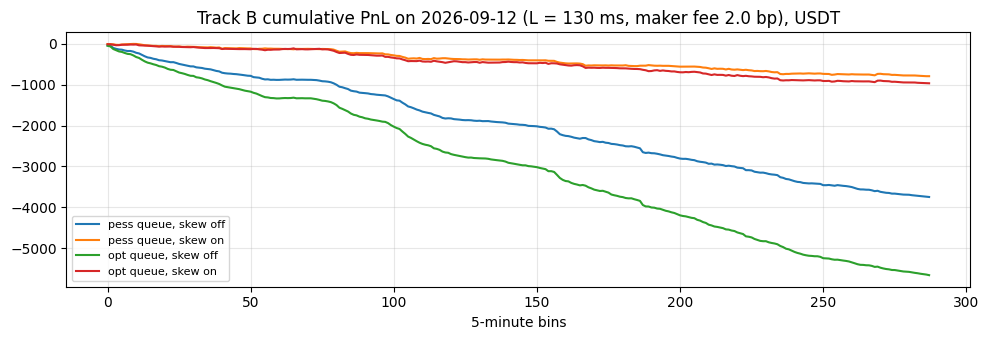

In [10]:
E = load_events_day(SEL); mid_px = float(np.nanmedian((E['bp1'] + E['ap1']) / 2)) / 100     # USDT per ETH, for conversions
tick_usdt = 0.01; rows = []; paths = {}
for L in LAT_GRID:
    for opt in (False, True):
        for th in (1e9, THETA_B):
            res, p5 = run_mm(SEL, E, L, th, opt)
            rows.append(dict(latency_ms=L, queue='optimistic' if opt else 'pessimistic', skew_mode='off' if th >= 1e8 else f'on (θ={th})', **res)); paths[(L, opt, th)] = p5
TB = pd.DataFrame(rows)
for c in [c for c in TB.columns if c.endswith('_ticks')]: TB[c.replace('_ticks', '_usdt')] = TB[c] * tick_usdt
show = ['latency_ms', 'queue', 'skew_mode', 'fills', 'eth_traded', 'gross_usdt', 'fees_usdt', 'net_usdt', 'spread_capture_usdt', 'adverse_selection_5s_usdt',
        'inventory_residual_usdt', 'breakeven_maker_fee_bp', 'markout_0.1s_ticks_per_eth', 'markout_1s_ticks_per_eth', 'markout_5s_ticks_per_eth', 'markout_30s_ticks_per_eth',
        'hit_rate_5s', 'max_abs_inventory_eth', 'sharpe_daily']
display(TB[[c for c in show if c in TB.columns]].round(3))
fee_tab = TB[['latency_ms', 'queue', 'skew_mode', 'gross_ticks', 'notional_ticks']].copy()
for fm in FEE_GRID['maker']: fee_tab[f'net_usdt_maker_{fm}bp'] = (fee_tab.gross_ticks - fm / 1e4 * fee_tab.notional_ticks) * tick_usdt
print('net PnL (USDT) across the pre-registered maker-fee grid:'); display(fee_tab.drop(columns=['gross_ticks', 'notional_ticks']).round(2))
capb = []
for q in (0.1, 1.0, 5.0):
    res, _ = run_mm(SEL, E, 130, THETA_B, False, q_eth=q); capb.append(dict(quote_eth=q, **{k: res.get(k) for k in ('fills', 'eth_traded', 'gross_ticks', 'breakeven_maker_fee_bp', 'markout_5s_ticks_per_eth')}))
capb = pd.DataFrame(capb); print('capacity (L = 130 ms, pessimistic, skew on):'); display(capb.round(3))
H = TB[(TB['latency_ms'] == 130) & (TB['queue'] == 'pessimistic') & (TB['skew_mode'] != 'off')].iloc[0]   # headline configuration
daily_std = H.pnl5_std_ticks * math.sqrt(288)
kill = {'max drawdown > 3 × daily PnL std': bool(H.max_drawdown_ticks > 3 * daily_std),
        '5 s markout worse than the spread captured (markout_5s < 0)': bool(H['markout_5s_ticks_per_eth'] < 0),
        f'alpha half-life ({HALF_LIFE_MS} ms) shorter than the send latency (130 ms)': bool(HALF_LIFE_MS < 130)}
print('kill criteria for the headline Track B configuration (L=130 ms, pessimistic, skew on):'); [print(('TRIGGERED  ' if v else 'ok         ') + k) for k, v in kill.items()]
fig, ax = plt.subplots(figsize=(10, 3.5))
for (L, opt, th), p5 in paths.items():
    if L == 130 and len(p5): ax.plot(np.cumsum(p5.pnl5) * tick_usdt, label=f"{'opt' if opt else 'pess'} queue, skew {'off' if th >= 1e8 else 'on'}")
ax.set_title(f'Track B cumulative PnL on {SEL} (L = 130 ms, maker fee {FEE_MAKER_BP} bp), USDT'); ax.set_xlabel('5-minute bins'); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); fig.savefig(REP / '07_trackB_pnl.png', dpi=110); plt.show()
TB.to_csv(REP / '07_trackB.csv', index=False); fee_tab.to_csv(REP / '07_trackB_fee_grid.csv', index=False); capb.to_csv(REP / '07_trackB_capacity.csv', index=False); calb.to_csv(REP / '07_trackB_calibration.csv', index=False)
del E; _ = gc.collect()

## Track C — directional taker
A taker round trip costs two taker fees plus about one tick of spread. At ETH ≈ 2,500 USDT, 1 tick ≈ 0.04 bp, so a 5 bp taker fee is about 125 ticks per side. Track C would trade only when |forecast| exceeds that cost.

In [11]:
fsel = RX[SEL]['f'][np.isfinite(RX[SEL]['f'])]; mid_t = mid_px / tick_usdt
cost_ticks = {ft: 2 * ft / 1e4 * mid_t + 1 for ft in FEE_GRID['taker']}
TC = pd.DataFrame([dict(taker_fee_bp=ft, round_trip_cost_ticks=c, max_abs_forecast_ticks=np.abs(fsel).max(), bins_exceeding=int((np.abs(fsel) > c).sum()),
                        p99_abs_forecast_ticks=np.percentile(np.abs(fsel), 99)) for ft, c in cost_ticks.items()])
display(TC.round(3)); TC.to_csv(REP / '07_trackC.csv', index=False)
print('Track C trades on the selection day:', int(TC.bins_exceeding.max()), '— forecasts of a few ticks cannot pay a round trip of ~100+ ticks' if TC.bins_exceeding.max() == 0 else '')

,taker_fee_bp,round_trip_cost_ticks,max_abs_forecast_ticks,bins_exceeding,p99_abs_forecast_ticks
0,2.5,127.156,70.624,0,8.504
1,4.0,202.849,70.624,0,8.504
2,5.0,253.311,70.624,0,8.504


Track C trades on the selection day: 0 — forecasts of a few ticks cannot pay a round trip of ~100+ ticks


In [12]:
best_A = TA[TA.latency_ms == 130].iloc[0]
lines = ['# 07 · Deep vs linear, strategy & execution (fit D1–D5, choices on D6; test days unopened)', '',
         f"Part A: complex model accepted = {accepted or 'none'}; trading signal = {SIGNAL_MODEL}",
         '  ' + '; '.join(f"{r.model} {r.target_s}s: dev-WF {r.oos_r2_dev_wf:.5f} / D6 {r.oos_r2_selection_day:.5f}" for r in r2.itertuples()),
         f"signal OOS R² on D6 (received clock, 1 s): {r2_sel:.5f}; alpha half-life {HALF_LIFE_MS} ms",
         f"Track A (L=130 ms, {PARENT_ETH} ETH / {PARENT_MIN} min, θ_A={THETA_A}): TWAP {best_A.twap_shortfall_bp:.3f} bp, OFI-timed {best_A.ofi_timed_shortfall_bp:.3f} bp, "
         f"saving {best_A.saving_bp:.3f} bp [95% CI {best_A.ci_lo:.3f}, {best_A.ci_hi:.3f}]",
         '  by latency: ' + '; '.join(f"L={r.latency_ms}: {r.saving_bp:.3f} [{r.ci_lo:.3f},{r.ci_hi:.3f}]" for r in TA.itertuples()),
         f"Track B (L=130, pessimistic, skew θ_B={THETA_B}): net {H.net_ticks * tick_usdt:.2f} USDT at maker {FEE_MAKER_BP} bp; break-even maker fee {H.breakeven_maker_fee_bp:.3f} bp; "
         f"5 s markout {H['markout_5s_ticks_per_eth']:.3f} ticks/ETH; kill criteria triggered: {[k for k, v in kill.items() if v] or 'none'}",
         f"Track C: bins where |forecast| > round-trip cost: {int(TC.bins_exceeding.max())}",
         'Funding not modelled (no funding-rate data); holding periods are sub-hour.']
(REP / '07_summary.md').write_text('\n'.join(lines), encoding='utf-8'); print('\n'.join(lines))
print('\nSend me: reports/07_summary.md, 07_deep_vs_linear.csv, 07_deep_vs_linear_dm.csv, 07_latency_decay.csv, 07_trackA.csv, 07_trackA_capacity.csv, '
      '07_trackA_calibration.csv, 07_trackB.csv, 07_trackB_fee_grid.csv, 07_trackB_capacity.csv, 07_trackC.csv and the PNGs')

# 07 · Deep vs linear, strategy & execution (fit D1–D5, choices on D6; test days unopened)

Part A: complex model accepted = none; trading signal = linear
  linear_ofi1 1s: dev-WF 0.00920 / D6 0.00808; linear_ofi1 5s: dev-WF 0.00493 / D6 0.00572; linear_ofi1 30s: dev-WF 0.00125 / D6 0.00099; ridge_window 1s: dev-WF 0.03609 / D6 -0.00077; ridge_window 5s: dev-WF 0.02083 / D6 0.01797; ridge_window 30s: dev-WF 0.00357 / D6 0.00650; cnn 1s: dev-WF 0.01971 / D6 -0.01796; cnn 5s: dev-WF 0.01333 / D6 0.01225; cnn 30s: dev-WF 0.00266 / D6 0.00399
signal OOS R² on D6 (received clock, 1 s): -0.00691; alpha half-life inf ms
Track A (L=130 ms, 50 ETH / 10 min, θ_A=2.0): TWAP -0.161 bp, OFI-timed -0.366 bp, saving 0.205 bp [95% CI 0.173, 0.235]
  by latency: L=0: 0.215 [0.181,0.246]; L=50: 0.211 [0.178,0.243]; L=130: 0.205 [0.173,0.235]; L=250: 0.194 [0.161,0.227]
Track B (L=130, pessimistic, skew θ_B=1.0): net -790.65 USDT at maker 2.0 bp; break-even maker fee -1.350 bp; 5 s markout -24.742 ticks/